In [40]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score, learning_curve
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve, average_precision_score
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
df = pd.read_csv("/content/stroke_data.csv")

#Show dataset has loaded, search for missing values
print(df.head())
print("\nMissing values per column:")
print(df.isnull().sum())

         Age  Gender     SES  Hypertension  Heart_Disease        BMI  \
0  66.788137    Male  Medium             1              0  25.842521   
1  86.393609  Female  Medium             1              1  32.531061   
2  76.158579  Female  Medium             1              0  40.681244   
3  72.477870  Female     Low             0              1  33.003193   
4  59.881635    Male     Low             0              0  26.062443   

   Avg_Glucose  Diabetes Smoking_Status  Stroke  
0    96.428681         1        Current       1  
1   133.350068         0          Never       1  
2   111.489589         0          Never       0  
3   125.692465         0         Former       0  
4   123.218486         1          Never       1  

Missing values per column:
Age               0
Gender            0
SES               0
Hypertension      0
Heart_Disease     0
BMI               0
Avg_Glucose       0
Diabetes          0
Smoking_Status    0
Stroke            0
dtype: int64


In [41]:
df.head()

,Age,Gender,SES,Hypertension,Heart_Disease,BMI,Avg_Glucose,Diabetes,Smoking_Status,Stroke
0,66.788137,Male,Medium,1,0,25.842521,96.428681,1,Current,1
1,86.393609,Female,Medium,1,1,32.531061,133.350068,0,Never,1
2,76.158579,Female,Medium,1,0,40.681244,111.489589,0,Never,0
3,72.477870,Female,Low,0,1,33.003193,125.692465,0,Former,0
4,59.881635,Male,Low,0,0,26.062443,123.218486,1,Never,1


In [42]:

def get_basic_info(df):
    """Get basic information about the dataset"""
    print(f"🔹 Number of Rows: {df.shape[0]}")
    print(f"🔹 Number of Columns: {df.shape[1]}")
    print(f"🔹 Columns: {df.columns.tolist()}")
    print(f"🔹 Column Data Types: {df.dtypes}")
    print(f"🔹 Missing Values: {df.isnull().sum().sum()}")
    print(f"🔹 Missing Values (Per Column) : {df.isnull().sum()}")
    print(f"🔹 Missing Values (Per Column Percentage) : {(df.isnull().mean() * 100)}")
    print(f"🔹 Unique Values: {df.nunique()}")

In [43]:
get_basic_info(df)

🔹 Number of Rows: 10000
🔹 Number of Columns: 10
🔹 Columns: ['Age', 'Gender', 'SES', 'Hypertension', 'Heart_Disease', 'BMI', 'Avg_Glucose', 'Diabetes', 'Smoking_Status', 'Stroke']
🔹 Column Data Types: Age               float64
Gender             object
SES                object
Hypertension        int64
Heart_Disease       int64
BMI               float64
Avg_Glucose       float64
Diabetes            int64
Smoking_Status     object
Stroke              int64
dtype: object
🔹 Missing Values: 0
🔹 Missing Values (Per Column) : Age               0
Gender            0
SES               0
Hypertension      0
Heart_Disease     0
BMI               0
Avg_Glucose       0
Diabetes          0
Smoking_Status    0
Stroke            0
dtype: int64
🔹 Missing Values (Per Column Percentage) : Age               0.0
Gender            0.0
SES               0.0
Hypertension      0.0
Heart_Disease     0.0
BMI               0.0
Avg_Glucose       0.0
Diabetes          0.0
Smoking_Status    0.0
Stroke            0.

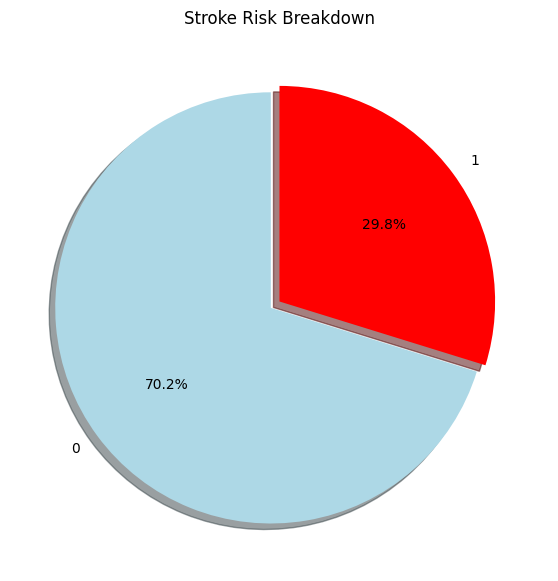

In [45]:
labels = df['Stroke'].value_counts(sort=True).index
sizes = df['Stroke'].value_counts(sort=True)

colors = ["lightblue", "red"]
explode = (0.05, 0)

plt.figure(figsize=(7, 7))
plt.pie(sizes[:2], explode=explode, labels=labels[:2], colors=colors, autopct='%1.1f%%', shadow=True, startangle=90)

plt.title('Stroke Risk Breakdown')
plt.show()

In [46]:
# Check for class imbalance
df['Stroke'].value_counts()/len(df)

,count
Stroke,
0,0.7022
1,0.2978


In [47]:
# Check for duplicates  --> ~0.015%
print("Duplicates:", df.duplicated().sum()/len(df))
df.drop_duplicates(inplace=True)

Duplicates: 0.0


In [48]:
df.columns

Index(['Age', 'Gender', 'SES', 'Hypertension', 'Heart_Disease', 'BMI',
       'Avg_Glucose', 'Diabetes', 'Smoking_Status', 'Stroke'],
      dtype='object')

In [49]:
# Encode categorical variables
le = LabelEncoder()
categorical_features = ['Gender', 'SES', 'Smoking_Status']
for feature in categorical_features:
    df[feature] = le.fit_transform(df[feature])


In [50]:
df.head(10)

,Age,Gender,SES,Hypertension,Heart_Disease,BMI,Avg_Glucose,Diabetes,Smoking_Status,Stroke
0,66.788137,1,2,1,0,25.842521,96.428681,1,0,1
1,86.393609,0,2,1,1,32.531061,133.350068,0,2,1
2,76.158579,0,2,1,0,40.681244,111.489589,0,2,0
3,72.477870,0,1,0,1,33.003193,125.692465,0,1,0
4,59.881635,1,1,0,0,26.062443,123.218486,1,2,1
5,59.880627,0,1,1,0,30.804901,108.172006,0,2,0
6,54.282589,0,1,1,0,28.452978,123.136954,0,2,1
7,81.030944,1,2,1,0,31.989033,125.504802,0,2,1
8,72.541330,1,2,1,0,22.966597,112.381248,0,1,0
9,75.449812,1,1,1,0,29.789860,139.371353,0,2,0


In [51]:
def handle_binary_missing(df, binary_cols, imputation_method='mode'):
    """
    Handle missing values for binary columns using specified imputation method.
    """

    for col in binary_cols:
        if imputation_method == 'mode':
            mode_value = df[col].mode()[0]
            df[col] = df[col].fillna(mode_value)
            print(f"🔹 Imputed missing values in binary column '{col}' with mode: {mode_value}")
        elif imputation_method == 'mean':
            mean_value = df[col].mean()
            df[col] = df[col].fillna(mean_value)
            print(f"🔹 Imputed missing values in binary column '{col}' with mean: {mean_value}")

    return df

In [52]:
def handle_categorical_missing(df, categorical_cols, imputation_method='mode'):
    """
    Handle missing values for categorical columns using specified imputation method.
    """

    for col in categorical_cols:
        if imputation_method == 'mode':
            mode_value = df[col].mode()[0]
            df[col] = df[col].fillna(mode_value)
            print(f"🔹 Imputed missing values in categorical column '{col}' with mode: {mode_value}")
        elif imputation_method == 'most_frequent':
            most_frequent_value = df[col].value_counts().idxmax()
            df[col] = df[col].fillna(most_frequent_value)
            print(f"🔹 Imputed missing values in categorical column '{col}' with most frequent: {most_frequent_value}")

    return df

In [53]:
def handle_numerical_missing(df, numerical_cols, imputation_method='median'):
    """
    Handle missing values for numerical columns using specified imputation method.
    """

    for col in numerical_cols:
        if df[col].dtype in ['int64', 'float64']:
            if imputation_method == 'mean':
                mean_value = df[col].mean()
                df[col] = df[col].fillna(mean_value)
                print(f"🔹 Imputed missing values in numerical column '{col}' with mean: {mean_value}")
            elif imputation_method == 'median':
                median_value = df[col].median()
                df[col] = df[col].fillna(median_value)
                print(f"🔹 Imputed missing values in numerical column '{col}' with median: {median_value}")
            elif imputation_method == 'most_frequent':
                most_frequent_value = df[col].value_counts().idxmax()
                df[col] = df[col].fillna(most_frequent_value)
                print(f"🔹 Imputed missing values in numerical column '{col}' with most frequent: {most_frequent_value}")

    return df

In [54]:
def handle_multivariate_imputation(df, imputation_method='knn'):
    """
    Handle multivariate imputation using KNN or Iterative Imputer.
    """

    if imputation_method == 'knn':
        print("🔹 Applying KNN Imputer...")
        knn_imputer = KNNImputer(n_neighbors=5)
        df_imputed = pd.DataFrame(knn_imputer.fit_transform(df), columns=df.columns)
        print("🔹 KNN Imputation applied.")
    else:
        print("❌ Invalid multivariate imputation method chosen.")
        return df

    return df_imputed

In [55]:
def handle_fill(df, fill_method='forward'):
    """
    Handle missing values using forward or backward fill.
    """

    if fill_method == 'forward':
        print("🔹 Applying forward fill...")
        df.fillna(method='ffill', inplace=True)
        print("🔹 Forward fill applied successfully.")
    elif fill_method == 'backward':
        print("🔹 Applying backward fill...")
        df.fillna(method='bfill', inplace=True)
        print("🔹 Backward fill applied successfully.")
    else:
        print("❌ Invalid fill method chosen.")

    return df

In [56]:
def classify_columns(df):
    """
    Classify columns into binary, numerical, and categorical types.
    """
    binary_cols = []
    numerical_cols = []
    categorical_cols = []

    for col in df.columns:
        if df[col].dtype in ['int64', 'float64']:
            if df[col].nunique() == 2:
                binary_cols.append(col)
            else:
                numerical_cols.append(col)
        elif df[col].dtype == 'object' or df[col].dtype.name == 'category':
            if df[col].nunique() == 2:
                binary_cols.append(col)
            else:
                categorical_cols.append(col)

    return {
        'binary': binary_cols,
        'numerical': numerical_cols,
        'categorical': categorical_cols
    }

In [57]:
classify_columns(df)

{'binary': ['Gender', 'Hypertension', 'Heart_Disease', 'Diabetes', 'Stroke'],
 'numerical': ['Age', 'SES', 'BMI', 'Avg_Glucose', 'Smoking_Status'],
 'categorical': []}

In [59]:
def filter_columns_by_null_percentage(df, column_classification, threshold=0.1):
    """
    Filters out columns from the classification lists that have more than the specified threshold of missing values.
    """
    filtered_classification = {'binary': [], 'numerical': [], 'categorical': []}
    missing_percentage = df.isnull().mean()

    for col_type in column_classification:
        for col in column_classification[col_type]:
            if missing_percentage[col] <= threshold:
                filtered_classification[col_type].append(col)
            else:
                print(f"🔹 Column '{col}' has more than {threshold*100}% missing values and is removed.")

    return filtered_classification

In [60]:
column_classification = {
    'binary': ['Gender', 'Hypertension', 'Heart_Disease', 'Diabetes', 'Stroke'],
 'numerical': ['Age', 'SES', 'BMI', 'Avg_Glucose', 'Smoking_Status'],
 'categorical': []
}

filtered_classification = filter_columns_by_null_percentage(df, column_classification, threshold=0.1)
print(filtered_classification)

{'binary': ['Gender', 'Hypertension', 'Heart_Disease', 'Diabetes', 'Stroke'], 'numerical': ['Age', 'SES', 'BMI', 'Avg_Glucose', 'Smoking_Status'], 'categorical': []}


In [61]:
handle_binary_missing(df, filtered_classification["binary"], imputation_method='mode')

🔹 Imputed missing values in binary column 'Gender' with mode: 0
🔹 Imputed missing values in binary column 'Hypertension' with mode: 1
🔹 Imputed missing values in binary column 'Heart_Disease' with mode: 0
🔹 Imputed missing values in binary column 'Diabetes' with mode: 0
🔹 Imputed missing values in binary column 'Stroke' with mode: 0


,Age,Gender,SES,Hypertension,Heart_Disease,BMI,Avg_Glucose,Diabetes,Smoking_Status,Stroke
0,66.788137,1,2,1,0,25.842521,96.428681,1,0,1
1,86.393609,0,2,1,1,32.531061,133.350068,0,2,1
2,76.158579,0,2,1,0,40.681244,111.489589,0,2,0
3,72.477870,0,1,0,1,33.003193,125.692465,0,1,0
4,59.881635,1,1,0,0,26.062443,123.218486,1,2,1
...,...,...,...,...,...,...,...,...,...,...
9995,80.647182,0,2,1,1,28.283629,128.639802,0,1,1
9996,82.607321,0,2,1,1,31.148301,105.025226,1,0,1
9997,86.020702,0,0,1,1,32.641037,147.174095,0,2,1
9998,67.387542,0,2,0,1,29.946547,112.480515,0,1,0


In [62]:
handle_numerical_missing(df, filtered_classification["numerical"], imputation_method='most_frequent')

🔹 Imputed missing values in numerical column 'Age' with most frequent: 83.32155674445578
🔹 Imputed missing values in numerical column 'SES' with most frequent: 2
🔹 Imputed missing values in numerical column 'BMI' with most frequent: 18.499628792555256
🔹 Imputed missing values in numerical column 'Avg_Glucose' with most frequent: 101.40067803054852
🔹 Imputed missing values in numerical column 'Smoking_Status' with most frequent: 2


,Age,Gender,SES,Hypertension,Heart_Disease,BMI,Avg_Glucose,Diabetes,Smoking_Status,Stroke
0,66.788137,1,2,1,0,25.842521,96.428681,1,0,1
1,86.393609,0,2,1,1,32.531061,133.350068,0,2,1
2,76.158579,0,2,1,0,40.681244,111.489589,0,2,0
3,72.477870,0,1,0,1,33.003193,125.692465,0,1,0
4,59.881635,1,1,0,0,26.062443,123.218486,1,2,1
...,...,...,...,...,...,...,...,...,...,...
9995,80.647182,0,2,1,1,28.283629,128.639802,0,1,1
9996,82.607321,0,2,1,1,31.148301,105.025226,1,0,1
9997,86.020702,0,0,1,1,32.641037,147.174095,0,2,1
9998,67.387542,0,2,0,1,29.946547,112.480515,0,1,0


In [64]:
df['Stroke'].value_counts()/len(df)

,count
Stroke,
0,0.7022
1,0.2978


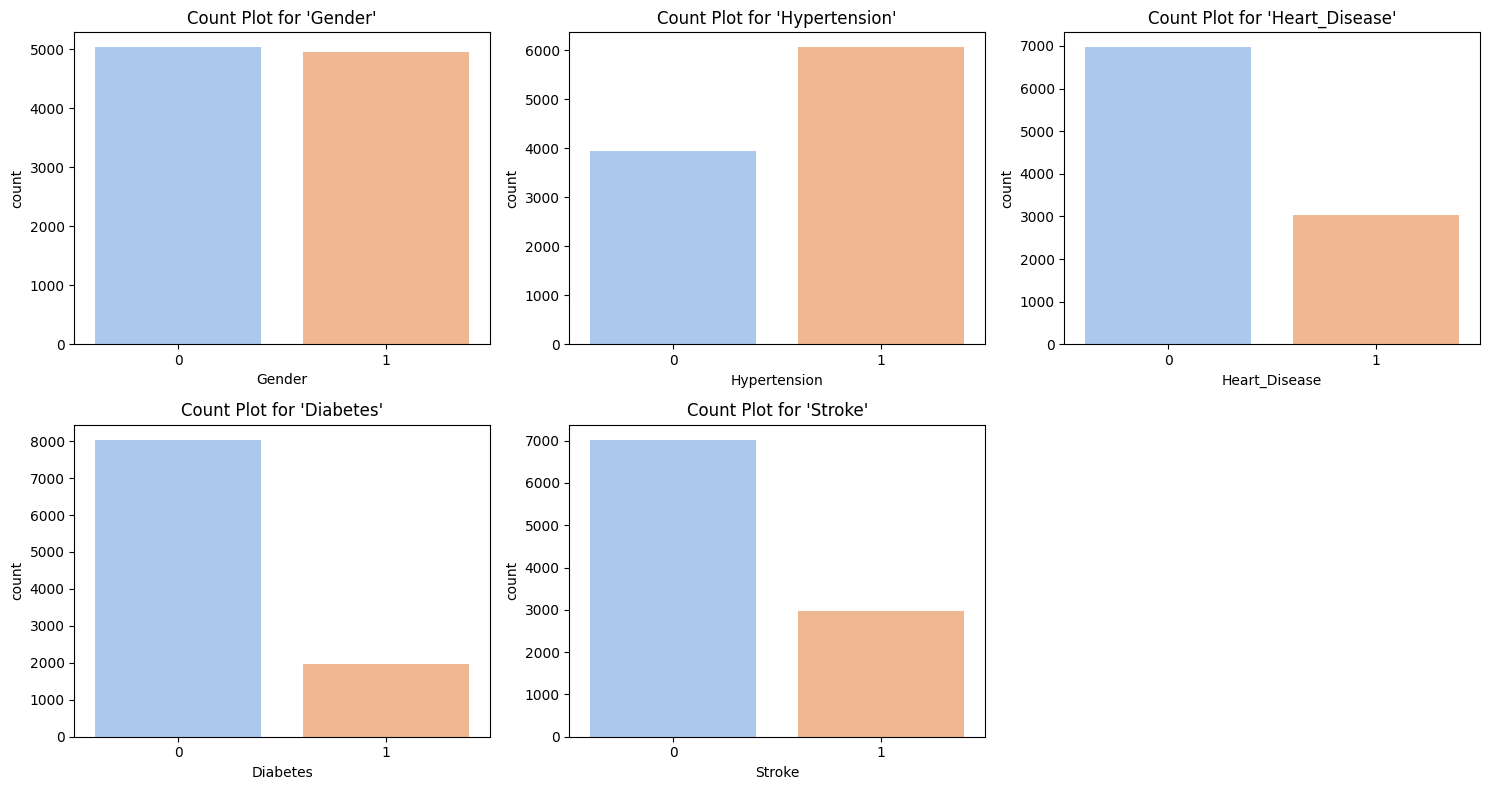

In [65]:


# Select binary columns (only those with 2 unique values: 0 and 1)
binary_cols = [col for col in df.columns if df[col].nunique() == 2 and df[col].dtype in ['int64', 'float64']]

# Plot count plots for each binary feature
num_plots = len(binary_cols)
num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 4))
axes = axes.flatten()

for i, col in enumerate(binary_cols):
    sns.countplot(x=col, data=df, ax=axes[i], palette='pastel')
    axes[i].set_title(f"Count Plot for '{col}'")
    axes[i].set_xticks([0, 1])

# Hide unused subplots if any
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [66]:
def plot_binary_countplots(df, binary_cols):
    """Plot count plots for binary features to visualize 0/1 distributions."""
    num_plots = len(binary_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()

    for i, col in enumerate(binary_cols):
        sns.countplot(x=col, data=df, palette='pastel', ax=axes[i])
        axes[i].set_title(f"Count Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")

    for j in range(num_plots, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()


In [67]:
def remove_outliers(df, numerical_cols, method="IQR"):
    """Remove rows containing outliers from numerical columns using IQR or Z-score."""
    df_clean = df.copy()

    for col in numerical_cols:
        if method == "IQR":
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
        elif method == "Z-score":
            mean = df[col].mean()
            std_dev = df[col].std()
            df_clean = df_clean[(np.abs((df[col] - mean) / std_dev) < 3)]

        print(f"🔹 Outliers removed in column '{col}' using {method} method.")

    return df_clean

In [68]:
def remove_outliers(df, numerical_cols, method="IQR"):
    """Remove rows containing outliers from non-binary numerical columns using IQR or Z-score."""
    df_clean = df.copy()

    for col in numerical_cols:
        unique_vals = df[col].dropna().unique()
        if len(unique_vals) <= 2 and set(unique_vals).issubset({0, 1}):
            print(f"⏭️ Skipping binary column '{col}' (only 0 and 1).")
            continue

        if method == "IQR":
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
        elif method == "Z-score":
            mean = df[col].mean()
            std_dev = df[col].std()
            df_clean = df_clean[(np.abs((df[col] - mean) / std_dev) < 3)]

        print(f"🔹 Outliers removed in column '{col}' using {method} method.")

    return df_clean


In [69]:
from scipy.stats.mstats import winsorize
import numpy as np

def transform_outliers(df, numerical_cols, method="winsorize"):
    """Transform outliers in non-binary numerical columns using winsorization, log, or square root transformation."""
    df_transformed = df.copy()

    for col in numerical_cols:
        unique_vals = df[col].dropna().unique()
        if len(unique_vals) <= 2 and set(unique_vals).issubset({0, 1}):
            print(f"⏭️ Skipping binary column '{col}' (only 0 and 1).")
            continue

        if method == "winsorize":
            df_transformed[col] = winsorize(df[col], limits=[0.05, 0.05])
        elif method == "log":
            df_transformed[col] = np.log1p(df[col])
        elif method == "sqrt":
            df_transformed[col] = np.sqrt(df[col])

        print(f"🔹 Outliers in '{col}' transformed using {method} method.")

    return df_transformed


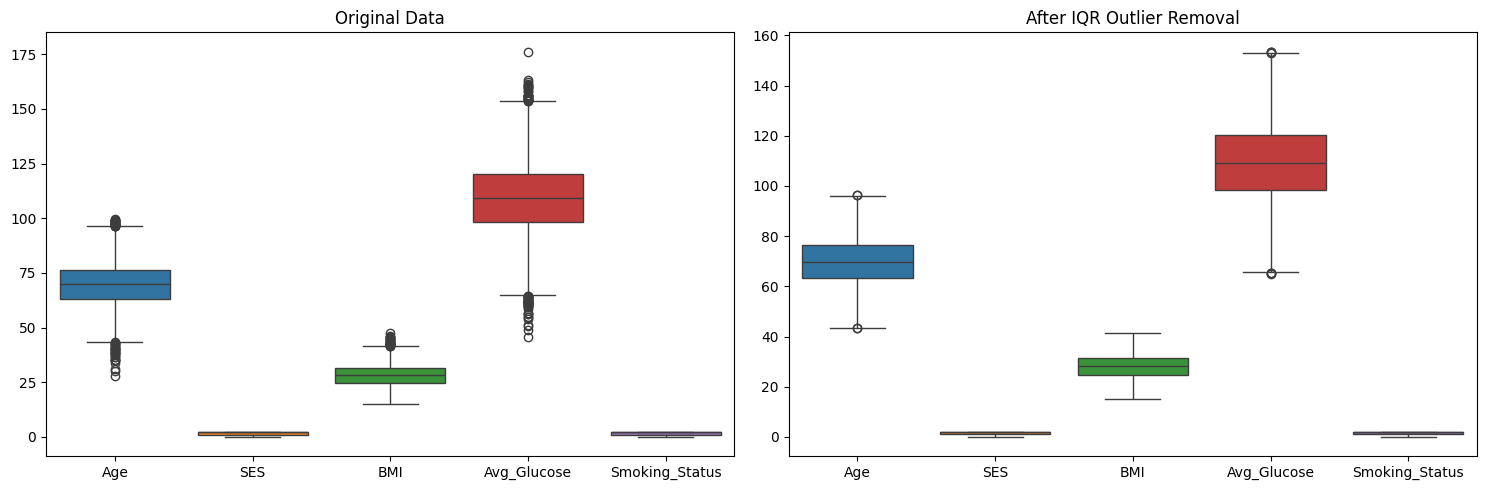

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

# Outlier removal function
def remove_outliers(df, num_cols, method="IQR"):
    df_clean = df.copy()
    for col in num_cols:
        if method == "IQR":
            Q1, Q3 = df[col].quantile([0.25, 0.75])
            df_clean = df_clean[df[col].between(Q1-1.5*(Q3-Q1), Q3+1.5*(Q3-Q1))]
        elif method == "Z-score":
            df_clean = df_clean[np.abs(zscore(df[col])) < 3]
    return df_clean

# Boxplot comparison
def plot_outliers(df, num_cols, method="IQR"):
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 2, 1)
    sns.boxplot(data=df[num_cols])
    plt.title("Original Data")

    cleaned = remove_outliers(df, num_cols, method)
    plt.subplot(1, 2, 2)
    sns.boxplot(data=cleaned[num_cols])
    plt.title(f"After {method} Outlier Removal")
    plt.tight_layout()
    plt.show()
    return cleaned

# Usage
num_cols = ['Age', 'SES', 'BMI', 'Avg_Glucose', 'Smoking_Status']
cleaned_df = plot_outliers(df, num_cols, method="IQR")  # or "Z-score"

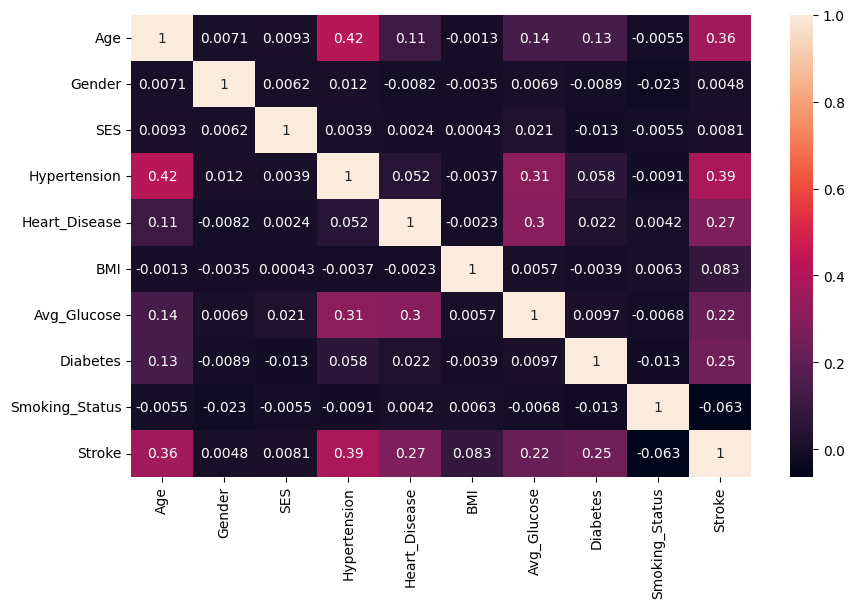

In [70]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(),annot=True)
plt.show()

In [ ]:
# Filter out binary columns from the list before passing to transform_outliers
transform_required_columns = ["Stroke"]

# Keep only non-binary numeric columns
valid_transform_columns = [col for col in transform_required_columns
                           if df[col].nunique() > 2 or not set(df[col].dropna().unique()).issubset({0, 1})]

# Apply transformation only if there's a valid column
if valid_transform_columns:
    df = transform_outliers(df, valid_transform_columns)
else:
    print("⚠️ No valid non-binary columns to transform.")


⚠️ No valid non-binary columns to transform.


In [73]:
# Define features and target variable
X = df.drop('Stroke', axis=1)
y = df['Stroke']


In [74]:
# Handle imbalanced dataset using SMOTE
# from imblearn.over_sampling import SMOTE
# sm = SMOTE(random_state=42)
# X_res, y_res = sm.fit_resample(X, y)
X = df.drop('Stroke', axis=1)
y = df['Stroke']

from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state=42)
X_res, y_res = ros.fit_resample(X, y)


In [75]:
# Split data into training, validation, and testing sets (60% train, 20% validation, 20% test)
X_train_full, X_test, y_train_full, y_test = train_test_split(X_res, y_res, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)


In [76]:
# Install necessary libraries
!pip install -U imbalanced-learn catboost dask[dataframe] shap lime

In [77]:
import numpy as np
import pandas as pd
import time
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, mean_absolute_error, mean_squared_error, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from imblearn.over_sampling import RandomOverSampler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import copy # Essential: This line imports the 'copy' module for deepcopy
import matplotlib.pyplot as plt # Added for plotting
import seaborn as sns # Added for plotting
import shap # Added for SHAP (Explainable AI)

In [78]:

def prepare_data(X, y):
    """
    Prepares train/val/test splits with oversampling.
    Applies RandomOverSampler on the minority class to balance the dataset,
    then splits the data into training, validation, and test sets,
    ensuring stratification to maintain class distribution.
    """

    from imblearn.over_sampling import BorderlineSMOTE

    from imblearn.over_sampling import RandomOverSampler
    ros = RandomOverSampler(random_state=42)
    X_res, y_res = ros.fit_resample(X, y)
    print(f"Balanced dataset shape after oversampling: X_res={X_res.shape}, y_res={y_res.shape}")

    # Split the balanced dataset into a full training set and a test set (80/20 split)
    # stratify=y_res ensures that the proportion of target classes is maintained in both splits
    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X_res, y_res, test_size=0.2, random_state=42, stratify=y_res
    )

    # Split the full training set into training and validation sets (75/25 split of train_full, effectively 60/20/20 overall)
    # stratify=y_train_full ensures class distribution is maintained in these splits as well
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=0.25, random_state=42, stratify=y_train_full
    )

    print(f"Training data shape: X_train={X_train.shape}, y_train={y_train.shape}")
    print(f"Validation data shape: X_val={X_val.shape}, y_val={y_val.shape}")
    print(f"Test data shape: X_test={X_test.shape}, y_test={y_test.shape}")
    return X_train, X_val, X_test, X_train_full, y_train, y_val, y_test, y_train_full

In [80]:
models = {
    'RandomForest': {
        'model': RandomForestClassifier(random_state=42, n_jobs=-1),
        'params': {
            'n_estimators': [100, 200], # Number of trees in the forest
            'max_depth': [None, 10, 20], # Maximum depth of the tree
            'min_samples_split': [2, 5], # Minimum number of samples required to split an internal node
            'class_weight': ['balanced'] # Adjusts weights inversely proportional to class frequencies
        }
    },
    'LogisticRegression': {
        # Using a Pipeline for Logistic Regression to include StandardScaler for numerical features
        'model': Pipeline([('scaler', StandardScaler()),
                           ('lr', LogisticRegression(random_state=42, max_iter=1000))]),
        'params': {
            'lr__C': [0.001, 0.01, 0.1, 1, 10], # Inverse of regularization strength
            'lr__penalty': ['l1', 'l2'], # Norm used in the penalization
            'lr__solver': ['liblinear'] # Algorithm to use in the optimization problem; 'liblinear' supports 'l1' and 'l2'
        }
    },
    'MLP': {
        # Using a Pipeline for MLPClassifier to include StandardScaler
        'model': Pipeline([('scaler', StandardScaler()),
                           ('mlp', MLPClassifier(random_state=42, early_stopping=True))]),
        'params': {
            'mlp__hidden_layer_sizes': [(50,), (100,), (50, 50)], # Number of neurons in hidden layers
            'mlp__activation': ['relu', 'tanh'], # Activation function for the hidden layer
            'mlp__alpha': [0.0001, 0.001], # L2 regularization term (strength)
            'mlp__learning_rate_init': [0.001, 0.01] # Initial learning rate
        }
    },
    'SVM': {
        # Using a Pipeline for SVC to include StandardScaler
        'model': Pipeline([('scaler', StandardScaler()),
                           ('svm', SVC(random_state=42, probability=True))]), # probability=True enables predict_proba
        'params': {
            'svm__C': [0.1, 1, 10], # Regularization parameter
            'svm__kernel': ['linear', 'rbf'], # Specifies the kernel type to be used in the algorithm
            'svm__gamma': ['scale', 'auto'] # Kernel coefficient for 'rbf', 'poly' and 'sigmoid'
        }
    },
    'NaiveBayes': {
        'model': GaussianNB(),
        'params': {
            'var_smoothing': [1e-9, 1e-8, 1e-7] # Portion of the largest variance of all features that is added to variances for calculation stability
        }
    },
    'ExtraTrees': {
        'model': ExtraTreesClassifier(random_state=42, n_jobs=-1),
        'params': {
            'n_estimators': [100, 200], # Number of trees in the forest
            'max_depth': [None, 10, 20], # Maximum depth of the tree
            'min_samples_split': [2, 5], # Minimum number of samples required to split an internal node
            'class_weight': ['balanced'] # Adjusts weights inversely proportional to class frequencies
        }
    },
    'GradientBoosting': {
        'model': GradientBoostingClassifier(random_state=42),
        'params': {
            'n_estimators': [100, 200], # Number of boosting stages
            'learning_rate': [0.01, 0.1], # Shrinkage factor applied to the contribution of each tree
            'max_depth': [3, 6], # Maximum depth of the individual regression estimators
            'subsample': [0.8, 1.0] # Fraction of samples to be used for fitting the individual base learners
        }
    },
    'XGBoost': {
        'model': XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss'),
        'params': {
            'n_estimators': [100, 200], # Number of boosting rounds
            'max_depth': [3, 6, 9], # Maximum depth of a tree
            'learning_rate': [0.01, 0.1], # Step size shrinkage to prevent overfitting
            # 'scale_pos_weight' will be added dynamically inside the evaluation function for imbalanced data
        }
    },
    'LightGBM': {
        'model': LGBMClassifier(random_state=42, n_jobs=-1),
        'params': {
            'n_estimators': [100, 200], # Number of boosting rounds
            'learning_rate': [0.01, 0.1], # Step size shrinkage
            'num_leaves': [31, 63], # Max number of leaves in one tree
            # 'scale_pos_weight' will be added dynamically inside the evaluation function for imbalanced data
        }
    },
    'CatBoost': {
        'model': CatBoostClassifier(random_state=42, verbose=0), # verbose=0 to suppress training output
        'params': {
            'iterations': [100, 200], # Number of boosting iterations
            'learning_rate': [0.01, 0.1], # Learning rate
            'depth': [4, 6], # Depth of the tree
            'auto_class_weights': ['Balanced'] # Automatically balances class weights
        }
    }
}

In [81]:
# Initialize Stratified K-Fold Cross-Validation
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)


In [82]:
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix,
    mean_squared_error, mean_absolute_error
)

# Initialize StratifiedKFold for classification (use KFold for regression)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Dictionary to store model results
model_results = {}

# Loop over each model
for model_name, model_info in models.items():
    print(f"\nTraining and tuning {model_name}...")
    start_time = time.time()

    model = model_info['model']
    param_grid = model_info['params']

    # Hyperparameter tuning with GridSearchCV
    search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring='f1',  # Use 'neg_mean_squared_error' for regression
        cv=skf,
        n_jobs=-1,
        verbose=1
    )
    search.fit(X_train, y_train)
    best_model = search.best_estimator_

    # Initialize lists to store all metrics
    accuracies, precisions, recalls, f1_scores, aucs = [], [], [], [], []
    mse_scores, mae_scores, rmse_scores = [], [], []
    tprs, fprs, specificities, npvs = [], [], [], []

    # Cross-validated evaluation
    for train_idx, val_idx in skf.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        best_model.fit(X_tr, y_tr)
        y_pred = best_model.predict(X_val)

        # Classification metrics
        accuracies.append(accuracy_score(y_val, y_pred))
        precisions.append(precision_score(y_val, y_pred, zero_division=0))
        recalls.append(recall_score(y_val, y_pred, zero_division=0))
        f1_scores.append(f1_score(y_val, y_pred, zero_division=0))

        # Regression metrics (on predicted probabilities)
        if hasattr(best_model, 'predict_proba'):
            y_proba = best_model.predict_proba(X_val)[:, 1]
            aucs.append(roc_auc_score(y_val, y_proba))
            mse_scores.append(mean_squared_error(y_val, y_proba))
            mae_scores.append(mean_absolute_error(y_val, y_proba))
            rmse_scores.append(np.sqrt(mean_squared_error(y_val, y_proba)))
        else:
            aucs.append(np.nan)
            mse_scores.append(np.nan)
            mae_scores.append(np.nan)
            rmse_scores.append(np.nan)

        # Confusion matrix metrics
        cm = confusion_matrix(y_val, y_pred)
        if cm.shape == (2, 2):
            tn, fp, fn, tp = cm.ravel()
            tprs.append(tp / (tp + fn) if (tp + fn) > 0 else 0)
            fprs.append(fp / (fp + tn) if (fp + tn) > 0 else 0)
            specificities.append(tn / (tn + fp) if (tn + fp) > 0 else 0)
            npvs.append(tn / (tn + fn) if (tn + fn) > 0 else 0)
        else:
            tprs.append(np.nan)
            fprs.append(np.nan)
            specificities.append(np.nan)
            npvs.append(np.nan)

    # Store all results
    model_results[model_name] = {
        "Best Params": search.best_params_,
        "Accuracy": np.mean(accuracies),
        "Precision": np.mean(precisions),
        "Recall": np.mean(recalls),
        "F1 Score": np.mean(f1_scores),
        "AUC": np.mean(aucs),
        "MSE (Proba)": np.mean(mse_scores),
        "MAE (Proba)": np.mean(mae_scores),
        "RMSE (Proba)": np.mean(rmse_scores),
        "Specificity": np.mean(specificities),
        "NPV": np.mean(npvs),
        "TPR": np.mean(tprs),
        "FPR": np.mean(fprs),
        "Training Time (s)": time.time() - start_time
    }

    # Print results
    print(f"\n{model_name} Results:")
    for metric, value in model_results[model_name].items():
        if isinstance(value, float):
            print(f"{metric}: {value:.4f}")
        else:
            print(f"{metric}: {value}")

# Convert results to DataFrame
results_df = pd.DataFrame(model_results).T
print("\nFinal Model Comparison:")
print(results_df.sort_values('F1 Score', ascending=False))


Training and tuning RandomForest...
Fitting 5 folds for each of 12 candidates, totalling 60 fits

RandomForest Results:
Best Params: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Accuracy: 0.8392
Precision: 0.8175
Recall: 0.8783
F1 Score: 0.8468
AUC: 0.9223
MSE (Proba): 0.1147
MAE (Proba): 0.2406
RMSE (Proba): 0.3387
Specificity: 0.7992
NPV: 0.8651
TPR: 0.8783
FPR: 0.2008
Training Time (s): 126.3246

Training and tuning LogisticRegression...
Fitting 5 folds for each of 10 candidates, totalling 50 fits

LogisticRegression Results:
Best Params: {'lr__C': 0.1, 'lr__penalty': 'l1', 'lr__solver': 'liblinear'}
Accuracy: 0.7681
Precision: 0.7618
Recall: 0.7889
F1 Score: 0.7750
AUC: 0.8499
MSE (Proba): 0.1583
MAE (Proba): 0.3171
RMSE (Proba): 0.3979
Specificity: 0.7468
NPV: 0.7754
TPR: 0.7889
FPR: 0.2532
Training Time (s): 0.9968

Training and tuning MLP...
Fitting 5 folds for each of 24 candidates, totalling 120 fits

MLP Results:
Best Params: {


Model Comparison Results:


,Best Params,Accuracy,Precision,Recall,F1 Score,AUC,MSE (Proba),MAE (Proba),RMSE (Proba),Specificity,NPV,TPR,FPR,Training Time (s)
RandomForest,"{'class_weight': 'balanced', 'max_depth': None...",0.839189,0.817475,0.878254,0.84677,0.92234,0.114733,0.240586,0.338687,0.799184,0.865071,0.878254,0.200816,126.324617
LogisticRegression,"{'lr__C': 0.1, 'lr__penalty': 'l1', 'lr__solve...",0.7681,0.761758,0.78888,0.774975,0.849856,0.158342,0.317109,0.397854,0.746814,0.775405,0.78888,0.253186,0.996798
MLP,"{'mlp__activation': 'relu', 'mlp__alpha': 0.00...",0.771779,0.770113,0.783022,0.77635,0.852837,0.156686,0.312022,0.395772,0.760273,0.774045,0.783022,0.239727,98.897059
SVM,"{'svm__C': 10, 'svm__gamma': 'scale', 'svm__ke...",0.772135,0.779763,0.766362,0.772915,0.837309,0.162925,0.326296,0.403606,0.778043,0.764836,0.766362,0.221957,654.748277
NaiveBayes,{'var_smoothing': 1e-09},0.754571,0.738783,0.797327,0.766858,0.844188,0.173103,0.276599,0.415897,0.710783,0.773816,0.797327,0.289217,0.416455
ExtraTrees,"{'class_weight': 'balanced', 'max_depth': None...",0.840258,0.826969,0.865349,0.845664,0.929573,0.109957,0.201592,0.331552,0.814554,0.855459,0.865349,0.185446,52.391995
GradientBoosting,"{'learning_rate': 0.1, 'max_depth': 6, 'n_esti...",0.819131,0.80133,0.854326,0.826969,0.897493,0.128762,0.25655,0.358775,0.78309,0.840024,0.854326,0.21691,195.034329
XGBoost,"{'learning_rate': 0.1, 'max_depth': 9, 'n_esti...",0.824947,0.806456,0.86066,0.832649,0.898353,0.128435,0.231949,0.358339,0.788371,0.846758,0.86066,0.211629,23.118272
LightGBM,"{'learning_rate': 0.1, 'n_estimators': 200, 'n...",0.818539,0.800237,0.854793,0.82657,0.89622,0.130167,0.236978,0.360763,0.781407,0.840246,0.854793,0.218593,94.625305
CatBoost,"{'auto_class_weights': 'Balanced', 'depth': 6,...",0.787206,0.788025,0.792867,0.790371,0.873286,0.144927,0.291157,0.380645,0.78141,0.786561,0.792867,0.21859,25.351329


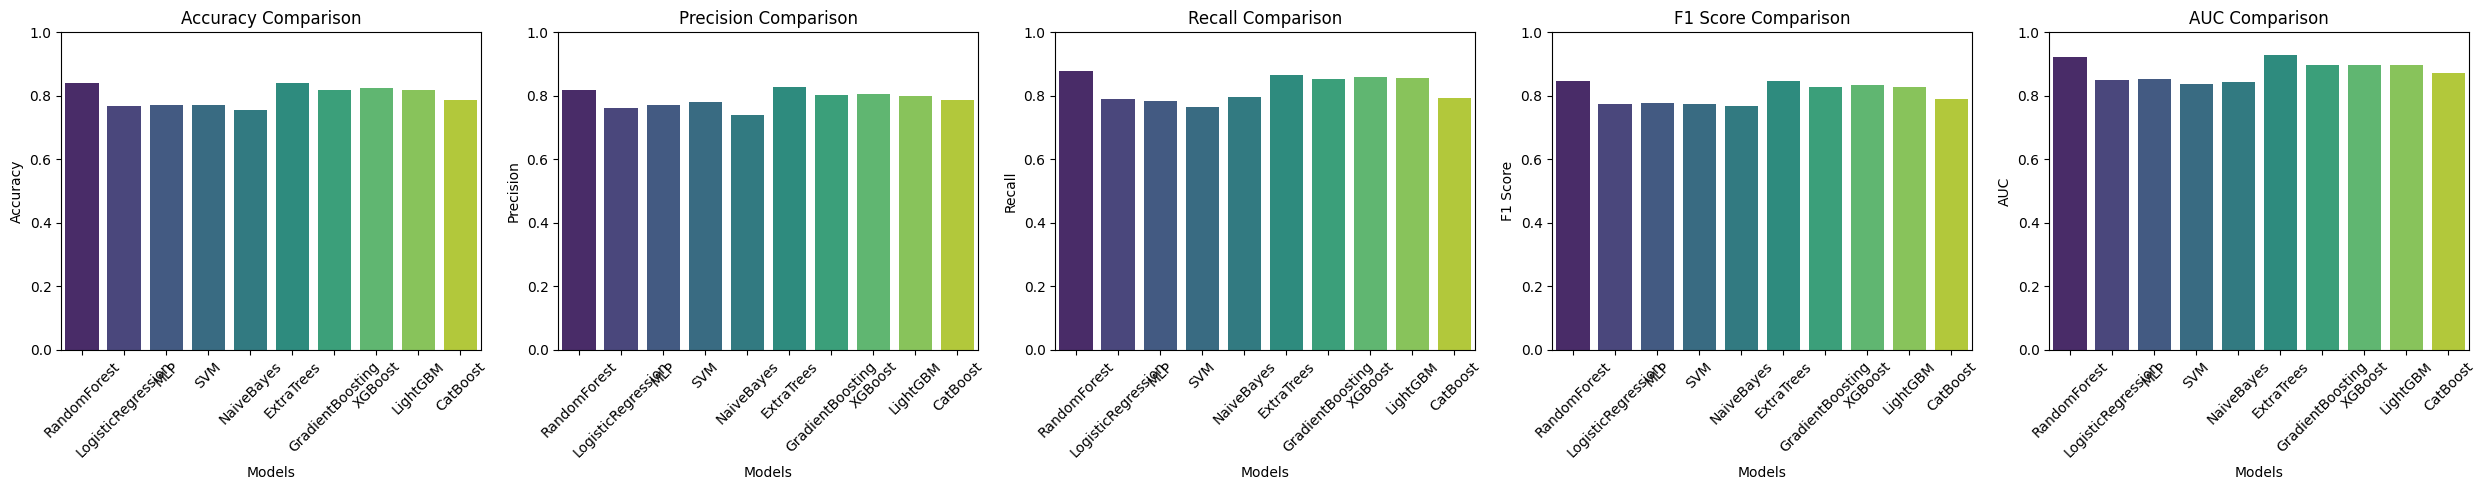

In [83]:
# Convert model results to a DataFrame for comparison
results_df = pd.DataFrame(model_results).T

# Display model performance comparison
print("\nModel Comparison Results:")
display(results_df)

# Plot comparison of each metric across models
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "AUC"]
fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for i, metric in enumerate(metrics):
    sns.barplot(x=results_df.index, y=results_df[metric], ax=axes[i], palette='viridis')
    axes[i].set_title(f"{metric} Comparison")
    axes[i].set_ylim(0, 1)
    axes[i].set_xlabel("Models")
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


In [84]:
from sklearn.ensemble import VotingClassifier

# Select the top 3 models based on F1 Score
top_models = results_df.sort_values(by='F1 Score', ascending=False).head(3).index.tolist()

# Initialize estimators with best parameters
estimators = []
for model_name in top_models:
    # Get the model configuration
    model_config = models[model_name]

    # For pipeline models, we need to set params differently
    if isinstance(model_config['model'], Pipeline):
        # Create new pipeline with best params
        best_params = model_results[model_name]['Best Params']
        model = model_config['model']

        # Set the parameters for the pipeline steps
        for param_name, param_value in best_params.items():
            step_name, param = param_name.split('__', 1)
            for step in model.steps:
                if step[0] == step_name:
                    setattr(step[1], param, param_value)
        estimators.append((model_name, model))
    else:
        # For regular models
        model = model_config['model'].set_params(**model_results[model_name]['Best Params'])
        estimators.append((model_name, model))

# Create VotingClassifier ensemble (soft voting for probability estimates)
ensemble_model = VotingClassifier(
    estimators=estimators,
    voting='soft',
    n_jobs=-1  # Use all available cores
)

# Train ensemble
print("\nTraining ensemble model with top 3 models:")
print(top_models)
start_time = time.time()
ensemble_model.fit(X_train, y_train)
training_time = time.time() - start_time

# Evaluate ensemble model using cross-validation (consistent with individual models)
cv_metrics = {
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1 Score': [],
    'AUC': [],
    'Specificity': [],
    'NPV': [],
    'TPR': [],
    'FPR': []
}

for train_idx, val_idx in skf.split(X_train, y_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    ensemble_model.fit(X_tr, y_tr)
    y_pred = ensemble_model.predict(X_val)
    y_proba = ensemble_model.predict_proba(X_val)[:, 1]

    # Calculate all metrics
    cv_metrics['Accuracy'].append(accuracy_score(y_val, y_pred))
    cv_metrics['Precision'].append(precision_score(y_val, y_pred, zero_division=0))
    cv_metrics['Recall'].append(recall_score(y_val, y_pred, zero_division=0))
    cv_metrics['F1 Score'].append(f1_score(y_val, y_pred, zero_division=0))
    cv_metrics['AUC'].append(roc_auc_score(y_val, y_proba))

    # Confusion matrix metrics
    cm = confusion_matrix(y_val, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        cv_metrics['Specificity'].append(tn / (tn + fp) if (tn + fp) > 0 else 0)
        cv_metrics['NPV'].append(tn / (tn + fn) if (tn + fn) > 0 else 0)
        cv_metrics['TPR'].append(tp / (tp + fn) if (tp + fn) > 0 else 0)
        cv_metrics['FPR'].append(fp / (fp + tn) if (fp + tn) > 0 else 0)
    else:
        cv_metrics['Specificity'].append(np.nan)
        cv_metrics['NPV'].append(np.nan)
        cv_metrics['TPR'].append(np.nan)
        cv_metrics['FPR'].append(np.nan)

# Calculate mean metrics
ensemble_results = {
    "Best Params": "VotingClassifier with: " + ", ".join(top_models),
    "Accuracy": np.mean(cv_metrics['Accuracy']),
    "Precision": np.mean(cv_metrics['Precision']),
    "Recall": np.mean(cv_metrics['Recall']),
    "F1 Score": np.mean(cv_metrics['F1 Score']),
    "AUC": np.mean(cv_metrics['AUC']),
    "Specificity": np.mean(cv_metrics['Specificity']),
    "NPV": np.mean(cv_metrics['NPV']),
    "TPR": np.mean(cv_metrics['TPR']),
    "FPR": np.mean(cv_metrics['FPR']),
    "Training Time (s)": training_time
}

# Add to results dataframe
ensemble_results_df = pd.DataFrame(ensemble_results, index=['Ensemble'])
results_df = pd.concat([results_df, ensemble_results_df])

# Print detailed results
print("\nEnsemble Model Performance (CV):")
print(f"Models used: {top_models}")
print(f"Accuracy: {ensemble_results['Accuracy']:.4f}")
print(f"Precision: {ensemble_results['Precision']:.4f}")
print(f"Recall: {ensemble_results['Recall']:.4f}")
print(f"F1 Score: {ensemble_results['F1 Score']:.4f}")
print(f"AUC: {ensemble_results['AUC']:.4f}")
print(f"Specificity: {ensemble_results['Specificity']:.4f}")
print(f"Training Time: {ensemble_results['Training Time (s)']:.2f}s")

# Final comparison showing ensemble vs individual models
print("\nFinal Model Comparison (Sorted by F1 Score):")
print(results_df.sort_values('F1 Score', ascending=False))


Training ensemble model with top 3 models:
['RandomForest', 'ExtraTrees', 'XGBoost']

Ensemble Model Performance (CV):
Models used: ['RandomForest', 'ExtraTrees', 'XGBoost']
Accuracy: 0.8404
Precision: 0.8214
Recall: 0.8747
F1 Score: 0.8472
AUC: 0.9257
Specificity: 0.8052
Training Time: 6.22s

Final Model Comparison (Sorted by F1 Score):
                                                          Best Params  \
Ensemble            VotingClassifier with: RandomForest, ExtraTree...   
RandomForest        {'class_weight': 'balanced', 'max_depth': None...   
ExtraTrees          {'class_weight': 'balanced', 'max_depth': None...   
XGBoost             {'learning_rate': 0.1, 'max_depth': 9, 'n_esti...   
GradientBoosting    {'learning_rate': 0.1, 'max_depth': 6, 'n_esti...   
LightGBM            {'learning_rate': 0.1, 'n_estimators': 200, 'n...   
CatBoost            {'auto_class_weights': 'Balanced', 'depth': 6,...   
MLP                 {'mlp__activation': 'relu', 'mlp__alpha': 0.00...   
Lo

In [85]:
# Add these metrics to your cv_metrics dictionary
cv_metrics = {
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1 Score': [],
    'AUC': [],
    'Specificity': [],
    'NPV': [],
    'TPR': [],
    'FPR': [],
    'MAE': [],       # New metric
    'MSE': [],       # New metric
    'RMSE': []       # New metric
}

for train_idx, val_idx in skf.split(X_train, y_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    ensemble_model.fit(X_tr, y_tr)
    y_pred = ensemble_model.predict(X_val)
    y_proba = ensemble_model.predict_proba(X_val)[:, 1]

    # Calculate all metrics
    cv_metrics['Accuracy'].append(accuracy_score(y_val, y_pred))
    cv_metrics['Precision'].append(precision_score(y_val, y_pred, zero_division=0))
    cv_metrics['Recall'].append(recall_score(y_val, y_pred, zero_division=0))
    cv_metrics['F1 Score'].append(f1_score(y_val, y_pred, zero_division=0))
    cv_metrics['AUC'].append(roc_auc_score(y_val, y_proba))

    # Regression metrics (using predicted probabilities)
    cv_metrics['MAE'].append(mean_absolute_error(y_val, y_proba))
    cv_metrics['MSE'].append(mean_squared_error(y_val, y_proba))
    cv_metrics['RMSE'].append(np.sqrt(mean_squared_error(y_val, y_proba)))

    # Confusion matrix metrics
    cm = confusion_matrix(y_val, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        cv_metrics['Specificity'].append(tn / (tn + fp) if (tn + fp) > 0 else 0)
        cv_metrics['NPV'].append(tn / (tn + fn) if (tn + fn) > 0 else 0)
        cv_metrics['TPR'].append(tp / (tp + fn) if (tp + fn) > 0 else 0)
        cv_metrics['FPR'].append(fp / (fp + tn) if (fp + tn) > 0 else 0)
    else:
        cv_metrics['Specificity'].append(np.nan)
        cv_metrics['NPV'].append(np.nan)
        cv_metrics['TPR'].append(np.nan)
        cv_metrics['FPR'].append(np.nan)

# Calculate mean metrics
ensemble_results = {
    "Best Params": "VotingClassifier with: " + ", ".join(top_models),
    "Accuracy": np.mean(cv_metrics['Accuracy']),
    "Precision": np.mean(cv_metrics['Precision']),
    "Recall": np.mean(cv_metrics['Recall']),
    "F1 Score": np.mean(cv_metrics['F1 Score']),
    "AUC": np.mean(cv_metrics['AUC']),
    "Specificity": np.mean(cv_metrics['Specificity']),
    "NPV": np.mean(cv_metrics['NPV']),
    "TPR": np.mean(cv_metrics['TPR']),
    "FPR": np.mean(cv_metrics['FPR']),
    "MAE": np.mean(cv_metrics['MAE']),       # New metric
    "MSE": np.mean(cv_metrics['MSE']),       # New metric
    "RMSE": np.mean(cv_metrics['RMSE']),     # New metric
    "Training Time (s)": training_time
}

# Add to results dataframe
ensemble_results_df = pd.DataFrame(ensemble_results, index=['Ensemble'])
results_df = pd.concat([results_df, ensemble_results_df])

# Print detailed results including the new metrics
print("\nEnsemble Model Performance (CV):")
print(f"Models used: {top_models}")
print(f"Accuracy: {ensemble_results['Accuracy']:.4f}")
print(f"Precision: {ensemble_results['Precision']:.4f}")
print(f"Recall: {ensemble_results['Recall']:.4f}")
print(f"F1 Score: {ensemble_results['F1 Score']:.4f}")
print(f"AUC: {ensemble_results['AUC']:.4f}")
print(f"Specificity: {ensemble_results['Specificity']:.4f}")
print(f"MAE: {ensemble_results['MAE']:.4f}")
print(f"MSE: {ensemble_results['MSE']:.4f}")
print(f"RMSE: {ensemble_results['RMSE']:.4f}")
print(f"Training Time: {ensemble_results['Training Time (s)']:.2f}s")

# Final comparison showing ensemble vs individual models
print("\nFinal Model Comparison (Sorted by F1 Score):")
print(results_df.sort_values('F1 Score', ascending=False))


Ensemble Model Performance (CV):
Models used: ['RandomForest', 'ExtraTrees', 'XGBoost']
Accuracy: 0.8404
Precision: 0.8214
Recall: 0.8747
F1 Score: 0.8472
AUC: 0.9257
Specificity: 0.8052
MAE: 0.2247
MSE: 0.1113
RMSE: 0.3336
Training Time: 6.22s

Final Model Comparison (Sorted by F1 Score):
                                                          Best Params  \
Ensemble            VotingClassifier with: RandomForest, ExtraTree...   
Ensemble            VotingClassifier with: RandomForest, ExtraTree...   
RandomForest        {'class_weight': 'balanced', 'max_depth': None...   
ExtraTrees          {'class_weight': 'balanced', 'max_depth': None...   
XGBoost             {'learning_rate': 0.1, 'max_depth': 9, 'n_esti...   
GradientBoosting    {'learning_rate': 0.1, 'max_depth': 6, 'n_esti...   
LightGBM            {'learning_rate': 0.1, 'n_estimators': 200, 'n...   
CatBoost            {'auto_class_weights': 'Balanced', 'depth': 6,...   
MLP                 {'mlp__activation': 'relu', 'ml

Attempting SHAP analysis...
TreeExplainer failed, trying KernelExplainer: Model type not yet supported by TreeExplainer: <class 'sklearn.ensemble._voting.VotingClassifier'>


  0%|          | 0/30 [00:00<?, ?it/s]

SHAP analysis failed: The shape of the shap_values matrix does not match the shape of the provided data matrix.
Falling back to permutation importance...


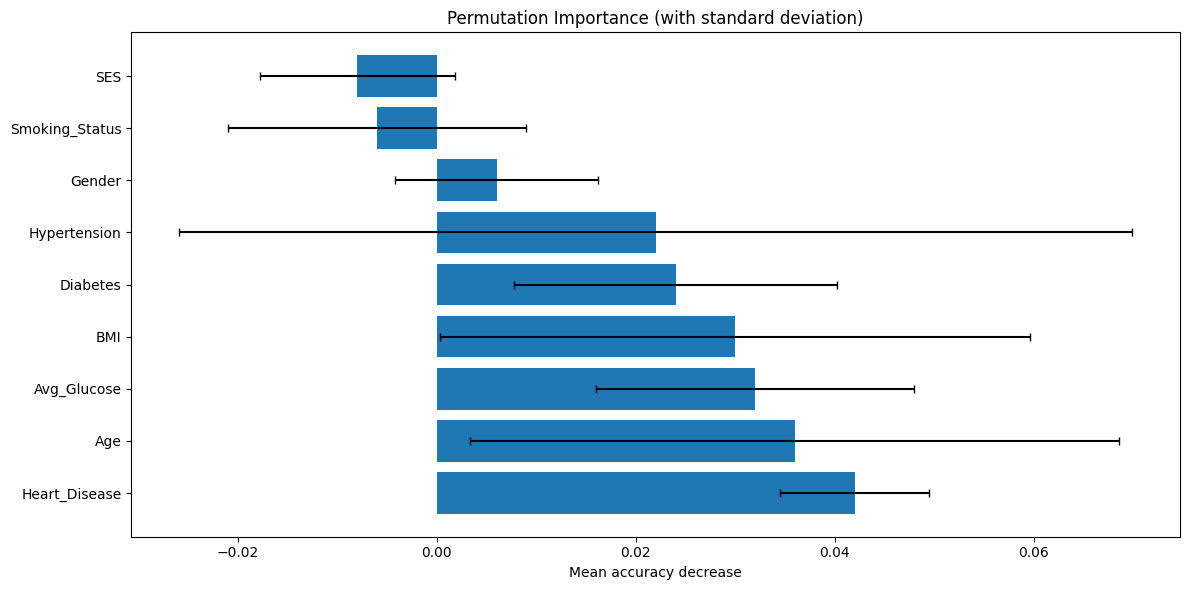

In [92]:
import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance

def plot_ensemble_explanations(ensemble_model, X_train, X_test, y_train=None, feature_names=None, n_samples=30):
    """
    Robust feature importance visualization for ensemble models with multiple fallback methods

    Parameters:
    - ensemble_model: Your trained ensemble model (VotingClassifier, Stacking, etc.)
    - X_train: Training data
    - X_test: Test data to explain
    - y_train: Training labels (required for permutation importance)
    - feature_names: List of feature names (optional)
    - n_samples: Number of instances to explain (default 30)
    """

    if feature_names is None:
        feature_names = X_train.columns.tolist()

    explain_data = X_test.iloc[:n_samples].copy()

    # Method 1: Try SHAP first (most advanced)
    shap_success = False
    try:
        print("Attempting SHAP analysis...")
        background = shap.sample(X_train, min(50, len(X_train)))

        # Determine appropriate explainer
        if hasattr(ensemble_model, 'predict_proba'):
            try:
                explainer = shap.TreeExplainer(ensemble_model, data=background)
                shap_values = explainer(explain_data)

                if len(shap_values.shape) == 3:  # Handle multi-output
                    shap_values = shap_values[..., 1]

                plt.figure(figsize=(12, 6))
                shap.summary_plot(shap_values, explain_data, feature_names=feature_names, show=False)
                plt.title("Ensemble Model: SHAP Value Distribution", fontsize=14)
                plt.tight_layout()
                plt.show()
                shap_success = True

            except Exception as e:
                print(f"TreeExplainer failed, trying KernelExplainer: {str(e)}")
                explainer = shap.KernelExplainer(
                    ensemble_model.predict_proba,
                    background,
                    nsamples=50
                )
                shap_values = explainer.shap_values(explain_data)[1]
                shap.summary_plot(shap_values, explain_data, feature_names=feature_names)
                shap_success = True

        if shap_success:
            return  # Successfully completed SHAP

    except Exception as e:
        print(f"SHAP analysis failed: {str(e)}")

    # Method 2: Permutation Importance (works for any model)
    if y_train is not None:
        print("Falling back to permutation importance...")
        try:
            # Fixed the parenthesis issue here
            X_sample = X_train.sample(min(100, len(X_train))) if len(X_train) > 100 else X_train
            y_sample = y_train.sample(min(100, len(y_train))) if len(y_train) > 100 else y_train

            result = permutation_importance(
                ensemble_model,
                X_sample,
                y_sample,
                n_repeats=5,
                random_state=42
            )

            importance_df = pd.DataFrame({
                'feature': feature_names,
                'importance_mean': result.importances_mean,
                'importance_std': result.importances_std
            }).sort_values('importance_mean', ascending=False)

            plt.figure(figsize=(12, 6))
            plt.barh(
                importance_df['feature'],
                importance_df['importance_mean'],
                xerr=importance_df['importance_std'],
                capsize=3
            )
            plt.title("Permutation Importance (with standard deviation)")
            plt.xlabel("Mean accuracy decrease")
            plt.tight_layout()
            plt.show()
            return

        except Exception as e:
            print(f"Permutation importance failed: {str(e)}")

    # Method 3: Simple feature importances from tree-based models
    print("Falling back to basic feature importances...")
    try:
        # Get feature importances from all base estimators
        all_importances = []
        if hasattr(ensemble_model, 'estimators_'):
            for est in ensemble_model.estimators_:
                if hasattr(est, 'feature_importances_'):
                    all_importances.append(est.feature_importances_)

        if all_importances:
            avg_importances = np.mean(all_importances, axis=0)
            std_importances = np.std(all_importances, axis=0)

            importance_df = pd.DataFrame({
                'feature': feature_names,
                'importance_mean': avg_importances,
                'importance_std': std_importances
            }).sort_values('importance_mean', ascending=False)

            plt.figure(figsize=(12, 6))
            plt.barh(
                importance_df['feature'],
                importance_df['importance_mean'],
                xerr=importance_df['importance_std'],
                capsize=3
            )
            plt.title("Average Feature Importance Across Base Models (with standard deviation)")
            plt.xlabel("Mean importance score")
            plt.tight_layout()
            plt.show()
            return

    except Exception as e:
        print(f"Basic feature importances failed: {str(e)}")

    # Final fallback: Coefficients for linear models
    print("Attempting coefficient visualization...")
    try:
        if hasattr(ensemble_model, 'coef_'):
            coefs = pd.Series(
                ensemble_model.coef_[0],
                index=feature_names
            ).sort_values()

            plt.figure(figsize=(12, 6))
            coefs.plot(kind='barh')
            plt.title("Model Coefficients")
            plt.tight_layout()
            plt.show()
            return

    except Exception as e:
        print(f"All explanation methods failed: {str(e)}")
        print("Consider using a different model or checking your data.")

# Usage example:
plot_ensemble_explanations(
    ensemble_model=ensemble_model,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,  # Make sure to pass y_train
    feature_names=X_train.columns.tolist()
)


Explaining instance 2000 (True class: 0, Predicted prob: 1.00)


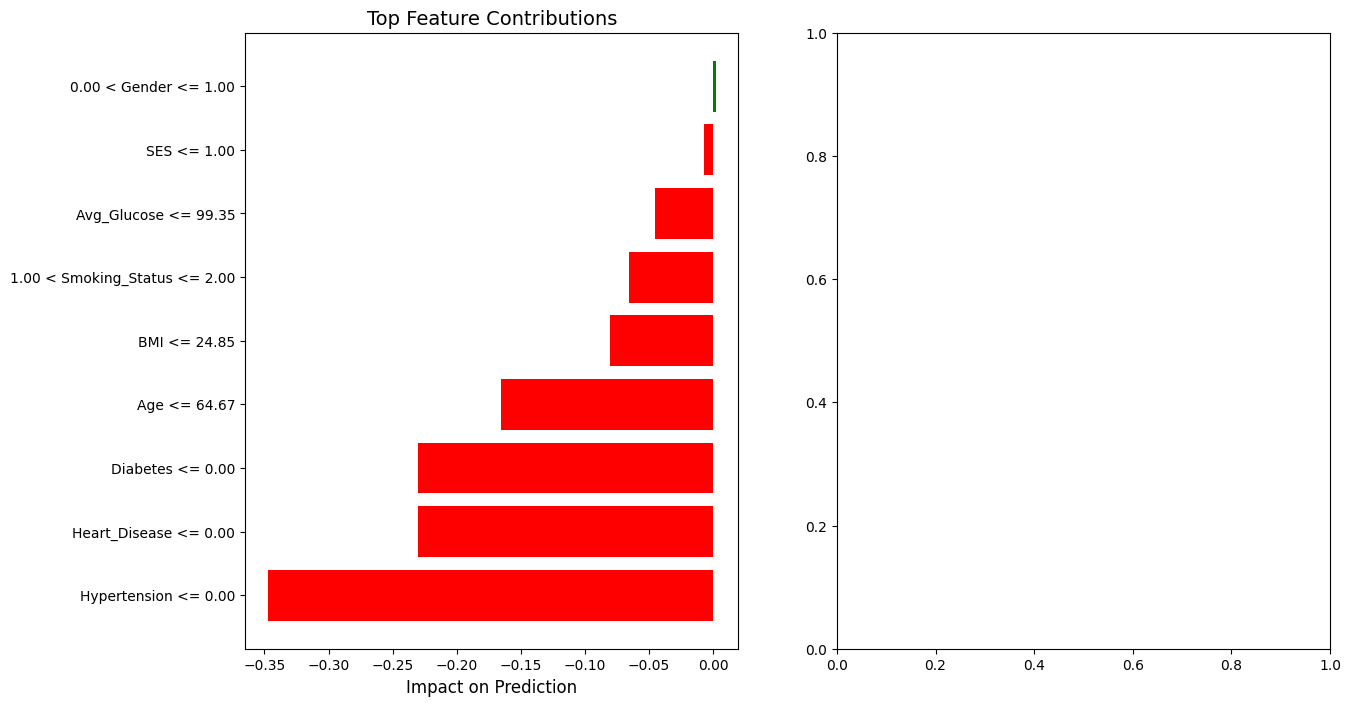

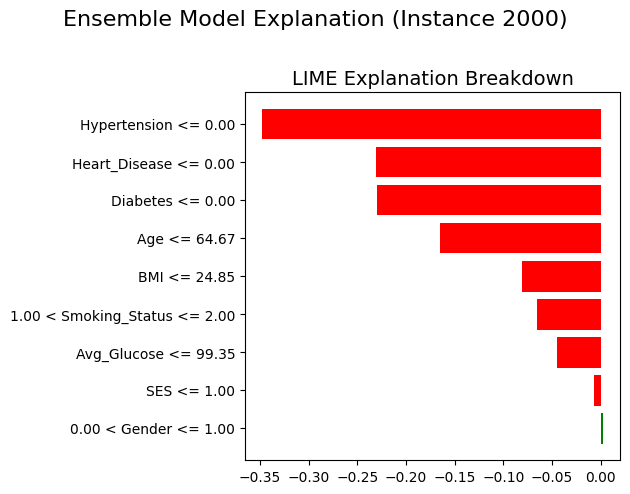

Successfully generated ensemble explanation plot


In [93]:
from lime import lime_tabular
from lime.lime_tabular import LimeTabularExplainer
import matplotlib.pyplot as plt
import numpy as np

def plot_lime_ensemble_explanation(ensemble_model, X_train, X_test, y_test, feature_names=None):
    """
    Generate and plot LIME explanation for ONE representative instance from ensemble model

    Args:
        ensemble_model: Trained VotingClassifier
        X_train: Training features (DataFrame)
        X_test: Test features (DataFrame)
        y_test: Test labels (for verification)
        feature_names: List of feature names to use
    """
    try:
        # Set default feature names if not provided
        feature_names = X_train.columns.tolist() if feature_names is None else feature_names
        X_test_array = X_test[feature_names].values

        # Initialize LIME explainer
        explainer = LimeTabularExplainer(
            training_data=X_train[feature_names].values,
            feature_names=feature_names,
            class_names=['No Stroke', 'Stroke'],
            mode='classification',
            random_state=42
        )

        # Select one representative instance (highest confidence correct prediction)
        pred_probs = ensemble_model.predict_proba(X_test_array)
        confidence = np.max(pred_probs, axis=1)
        correct_preds = (np.argmax(pred_probs, axis=1) == y_test.values)  # Fixed missing parenthesis
        sample_idx = np.argmax(confidence * correct_preds)

        print(f"\nExplaining instance {sample_idx} (True class: {y_test.iloc[sample_idx]}, "
              f"Predicted prob: {np.max(pred_probs[sample_idx]):.2f})")

        # Generate explanation
        exp = explainer.explain_instance(
            X_test_array[sample_idx],
            ensemble_model.predict_proba,
            num_features=10
        )

        # Single comprehensive plot
        plt.figure(figsize=(14, 8))

        # Left subplot - Feature importance
        plt.subplot(1, 2, 1)
        features = [x[0] for x in exp.as_list()]
        impacts = [x[1] for x in exp.as_list()]
        colors = ['green' if x > 0 else 'red' for x in impacts]

        plt.barh(features, impacts, color=colors)
        plt.title('Top Feature Contributions', fontsize=14)
        plt.xlabel('Impact on Prediction', fontsize=12)

        # Right subplot - LIME explanation
        plt.subplot(1, 2, 2)
        exp.as_pyplot_figure()
        plt.title('LIME Explanation Breakdown', fontsize=14)
        plt.gca().set_ylabel('')  # Remove redundant label

        plt.suptitle(f"Ensemble Model Explanation (Instance {sample_idx})", fontsize=16, y=1.02)
        plt.tight_layout()
        plt.show()

        return exp

    except Exception as e:
        print(f"LIME explanation failed: {str(e)}")
        return None

# Example usage
ensemble_exp = plot_lime_ensemble_explanation(
    ensemble_model=ensemble_model,
    X_train=X_train,
    X_test=X_test,
    y_test=y_test
)

if ensemble_exp:
    print("Successfully generated ensemble explanation plot")
else:
    print("Failed to generate explanation")